R2-R1:  0.38303032891872135
R2-R1:  0.38303032891872135
R2-R1:  0.38304654168950947
R2-R1:  0.38304654168950947
R2-R1:  0.3830627495863155
R2-R1:  0.3830627515362721
R2-R1:  0.3830789535850272
R2-R1:  0.3830789584580998
R2-R1:  0.3830951536856446
R2-R1:  0.383095162457721
R2-R1:  0.3831113498927152
R2-R1:  0.38311136353513575
R2-R1:  0.383127548048833
R2-R1:  0.38312755584320257
R2-R1:  0.38314374328365375
R2-R1:  0.38314374425863207
R2-R1:  0.38315993559717754
R2-R1:  0.38315992877960525
R2-R1:  0.38317612499122333
R2-R1:  0.3831761094106696
R2-R1:  0.38319231146488164
R2-R1:  0.3831922958861469
R2-R1:  0.38320848431067134
R2-R1:  0.3832084794403272
R2-R1:  0.3832246532656427
R2-R1:  0.3832246600804865
R2-R1:  0.3832408183316147
R2-R1:  0.3832408378002583
R2-R1:  0.3832569795113159
R2-R1:  0.3832570126023711
R2-R1:  0.38327315140122664
R2-R1:  0.38327316989125393
R2-R1:  0.3832893203725689
R2-R1:  0.3832893232938659
R2-R1:  0.38330548643079965
R2-R1:  0.383305472812026
R2-R1:  0.38332

"\n#The radius of the earth:\nR_Earth=6370\naxes.set_aspect( 1 )\naxes.set_xlim(0,500)\naxes.set_ylim(R_Earth,R_Earth+300)\n#circ=patch.Circle((0,-1*ray[-1][1]),2*ray[-1][1],fill=False) #A circle centered at (0,0) with radius 100\n#axes.add_artist( circ )\n#plt.title( 'Circle' )\nplt.show()\n"

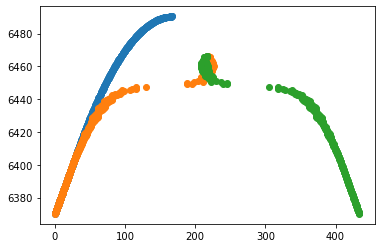

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patch
import scipy.optimize as optimize


#Import function to obtain electron density:
#Doesn't work
#from ipynb.fs.full.Refraction_index_from_electron_density import ref_index

%run "Refraction_index_from_electron_density.py"

freq = 5e7# Radiofrequency from 50 kHz to 300 GHz, we choose 100 kHz
n=ref_index(freq,elec_dens)


#And the grid distance:
delta_y=1

#We select the velocity of the light:
c=1

# NOW WE NEED TO DO ITERATIONS FOR DIFFERENT FREQUANCIES TO REACH THE END POINT:

destiny=1000 #The x position we want to reach

def GetRayPolar(angle,n):
    c=1
    delta_r=1
    
    #The radius of the earth:
    R_Earth=6370
    #We choose the initial position of the ray:
    ray=[[0,R_Earth]]
    
    #We just do iterations:
    step_t=0.5 #constant, time passing between iterations
    current_index=0 #To see in which pixel we are
    sum_r=0 #The sum of the distance from the centre, to see if it passes to the next cell

    #We track te iterations number too:
    i=0

    #A boolean to stop the iterations:
    boolean=True

    while boolean: 
        #The n index depends on the height:
        n0=n[current_index]
        x=step_t*c/n0*np.cos(angle)
        y=step_t*c/n0*np.sin(angle)
        # print("El pinche y:", y)
        #We need to see if we have reached the next height with this last step
        #To do so, we check if the sum is bigger than the grid size:
        '''
        print("sum of height: ",sum_h)
        print("refraction index: ",n0)
        print("angle: ", angle)
        print("current index: ", current_index)
        '''
        r2=np.sqrt((ray[i-1][0]+x)**2+(ray[i-1][1]+y)**2) #Distance from centre of earth to new point
        r1=np.sqrt((ray[i-1][0])**2+(ray[i-1][1])**2) #Distance from centre of earth to previous point
        print("R2-R1: ",(r2-r1))
        # print("PREVIOUS sum of height: ",sum_h0)
        if (abs(sum_r+(r2-r1))>=delta_r):
            k=1
            while(abs(sum_r+(r2-r1)-k*delta_r)>delta_r):
                k+=1
            n1=np.mean(n[current_index+1:current_index+k+1])
            # print("n1: ",n1)
            current_index+=k #We go to the next grid
            #See if changes refraction index:
            if (n1==n0):
                # print("n1 is equal to n0")
                #r2=np.sqrt((ray[i-1][0]+x)**2+(ray[i-1][1]+y)**2) #Distance from centre of earth to new point
                #r1=np.sqrt((ray[i-1][0])**2+(ray[i-1][1])**2) #Distance from centre of earth to previous point
                sum_r=sum_r+ (r2-r1) - k*delta_r #Goes to next cell normal
                phi0=np.arctan2((ray[i-1][1]+y),(ray[i-1][0]+x))
                ubre=(np.pi/2)-phi0
                x_rot=x*np.cos(ubre)-y*np.sin(ubre)
                y_rot=x*np.sin(ubre)+y*np.cos(ubre)
                #We add the new total position of our ray:
                ray.append([ray[i-1][0]+x_rot,ray[i-1][1]+y_rot])
                #ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
            else:
                #Snell law to calculate new angle.
                #CAUTION: Snell angle is taken from the normal and ours is from the horizontal axis:
                
                #First the angle from the horizontal:
                theta0=angle #angle0=angle
                
                #Then we need to calculate the angle from the horizontal (passing through the centre)
                #to the new vector position:
                phi0=np.arctan2((ray[i-1][1]+y),(ray[i-1][0]+x))
                
                #Finally, we get the angle to use Snell law. Using trigonometry:
                alpha0=phi0-theta0
                print("Alpha 0: ",alpha0*180/np.pi)
                print("Phi 0: ",phi0*180/np.pi)
                #CAREFUL: arcsin input has to be between -1 and 1. If it exceedes, add/substract 1
                if (n1==0 or abs((n0*np.sin(alpha0))/n1)>=1):
                    #There has been an internal reflection, the wave can't pass. We stop
                    boolean=False
                else:
                    # print("x expected: ",x)
                    # print("y expected: ",y)
                    # print("sum of y: ",sum_h)
                    # print("n0: ",n0)
                    # print("angle: ",angle0)
                    alpha_out=np.arcsin((n0*np.sin(alpha0))/n1)
                    theta=(np.pi/2)-alpha_out
                    print("Alpha: ",alpha_out*180/np.pi)
                    #Now we need to calculate the height.
                    #It divides into two heights:
                    #1)height in previous cell: delta_y-sum_h
                    #2)height in new cell with new angle and n:
                    y1=(delta_r-sum_r)
                    #vprint("y1: ",y1)
                   # print("THE FUCKING Y1: ",y1)
                    y2=(c/n1)*np.sin(theta)*(step_t-((delta_r-sum_r)*n0/(c*np.cos(alpha0))))
                    y=y1+y2
                    #vprint("y2: ",y2)
                    #The y can be negative, but the x is always positive (it moves forward)
                    x=abs(y1/np.tan(alpha0))+abs(y2/np.tan(alpha_out))
                    #print("x real: ",x)
                    #print("y real: ",y)
                    #print("n1: ",n1)
                    #print("angle: ",angle)
                    #We put the sum back to current height in next cell, to count again:
                    sum_r=y2 
                    ubre=(np.pi/2)-phi0
                    x_rot=x*np.cos(ubre)-y*np.sin(ubre)
                    y_rot=x*np.sin(ubre)+y*np.cos(ubre)
                    #We add the new total position of our ray:
                    ray.append([ray[i-1][0]+x_rot,ray[i-1][1]+y_rot])
                    angle=theta

        else:
            #If it doesn't jump to next cell the ray will travel normally:
            ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
            # print("El pinche y:", y)
            # print("The previous sum_h: ",sum_h)
            # print("la suma: ",sum_h+y)
            #sum_h=sum_h+y
            sum_r+=np.sqrt(x**2+y**2)
            # print("The new sum_h: ",sum_h)

        #Next iteration:
        i+=1
        # print(boolean)
    return ray



def GetLastPosition(angle):
    ray=GetRay(angle,n)
    return (ray[-1][0]-(destiny/2))


#Now We have the right angle:
#right_angle=optimize.fsolve(GetLastPosition,(50*np.pi/180))
#print(right_angle*180/np.pi)
ray=GetRay((50*np.pi/180),n)
ray2=GetRayPolar((50*np.pi/180),n)
#print(ray2)

#Draw a circle:


figure, axes = plt.subplots()


x_axis=[]
y_axis=[]
for j in range(len(ray)):
    x_axis.append(ray[j][0])
    y_axis.append(ray[j][1])
#print(y_axis)

axes.scatter(x_axis,y_axis)

x_axis2=[]
y_axis2=[]
for j in range(len(ray2)):
    x_axis2.append(ray2[j][0])
    y_axis2.append(ray2[j][1])
#print(y_axis2)

axes.scatter(x_axis2,y_axis2)


# ONCE WE HAVE THE CORRECT RAY WE DO AN ANDRES
destiny=ray2[-1][0]*2

andres=[]
for j in range (len(ray2)):
    andres.append([destiny-ray2[j][0],ray2[j][1]])
x_axis2=[]
y_axis2=[]
for j in range(len(andres)):
    x_axis2.append(andres[j][0])
    y_axis2.append(andres[j][1])
#print(y_axis)
axes.scatter(x_axis2,y_axis2)
'''
#The radius of the earth:
R_Earth=6370
axes.set_aspect( 1 )
axes.set_xlim(0,500)
axes.set_ylim(R_Earth,R_Earth+300)
#circ=patch.Circle((0,-1*ray[-1][1]),2*ray[-1][1],fill=False) #A circle centered at (0,0) with radius 100
#axes.add_artist( circ )
#plt.title( 'Circle' )
plt.show()
'''